Dataset shape: (768, 9)
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1   

Missing values after cleaning:
 Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outco

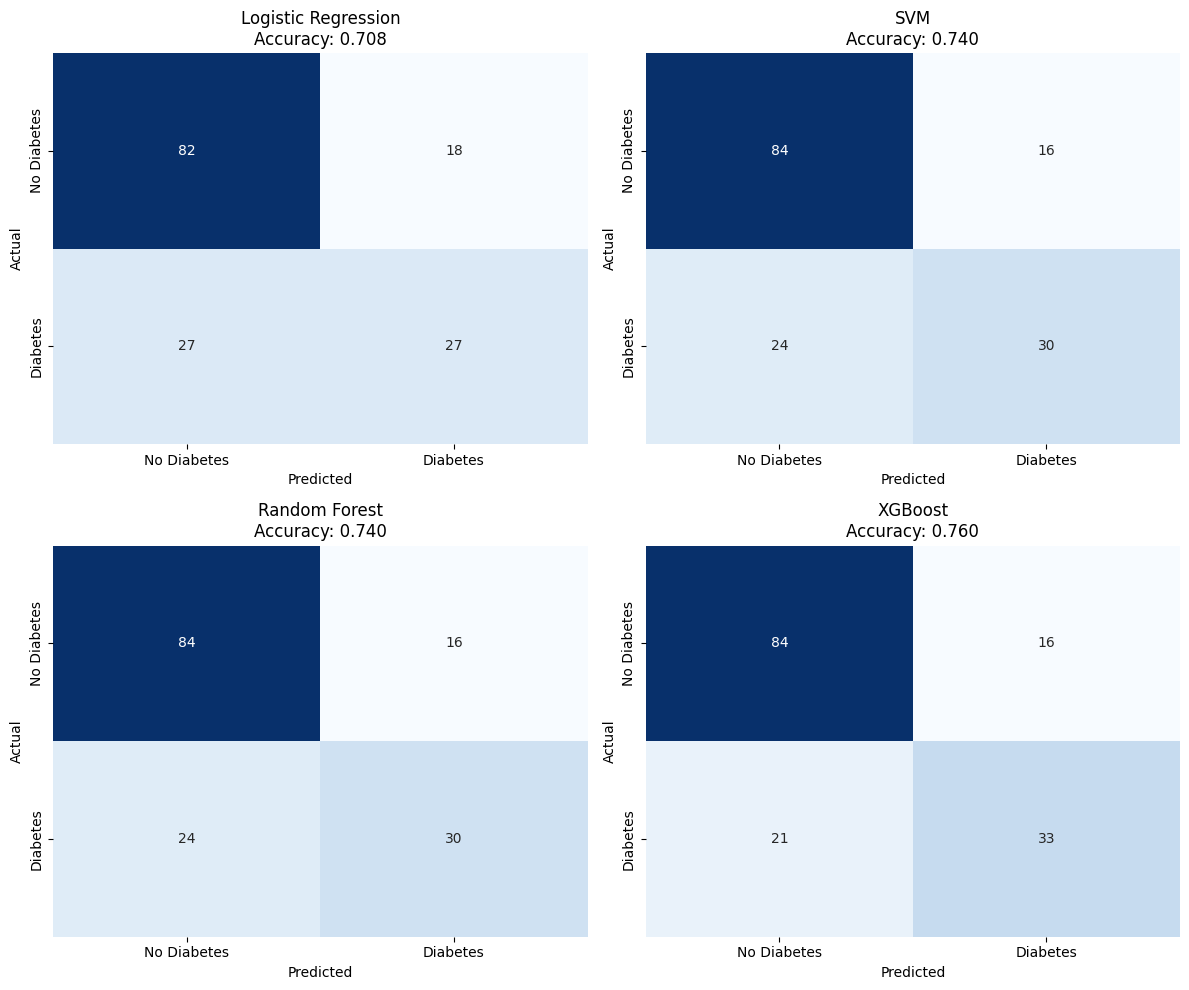

Saved ROC curve comparison -> roc_curve_comparison.png


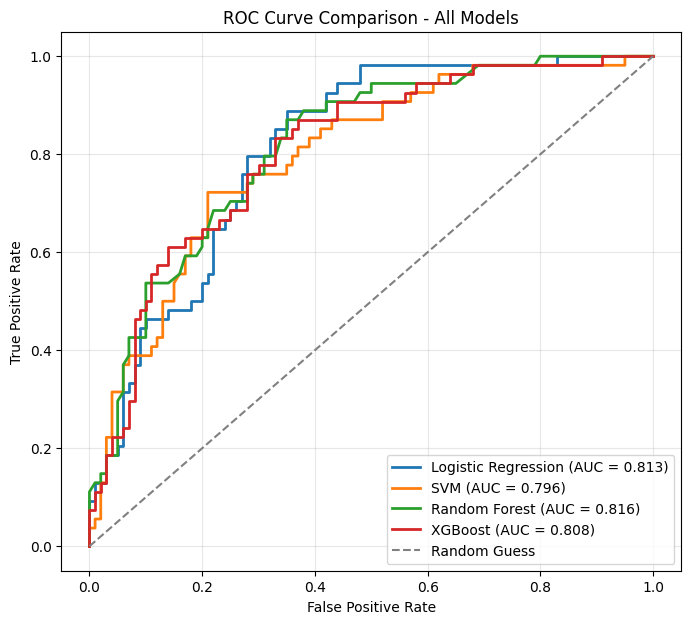


FINAL MODEL COMPARISON
                     Accuracy     AUC
XGBoost                0.7597  0.8081
SVM                    0.7403  0.7964
Random Forest          0.7403  0.8161
Logistic Regression    0.7078  0.8130

Saved model comparison chart -> model_comparison.png


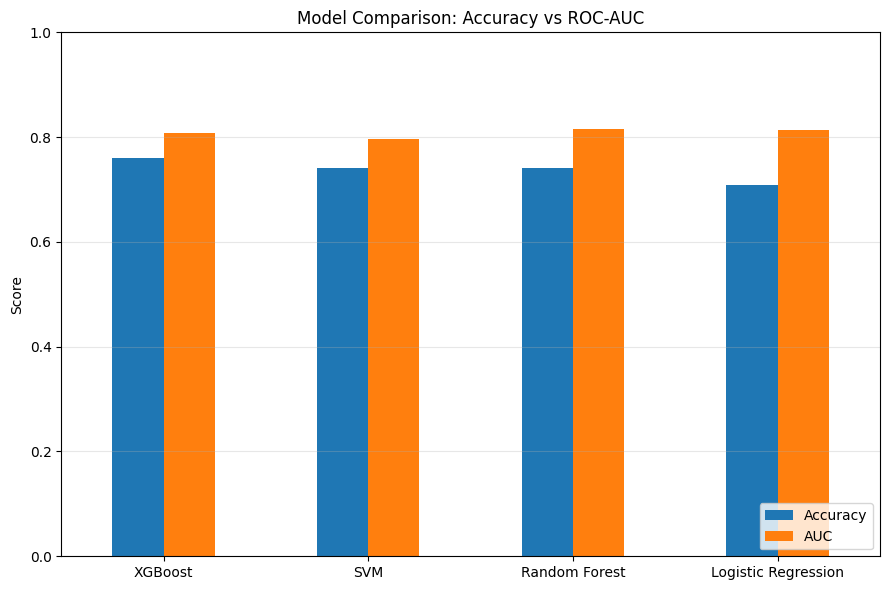


Best performing model (by Accuracy): XGBoost


In [2]:
"""
==================================================================
 TASK 4: Disease Prediction from Medical Data
 Dataset : diabetes.csv (Pima Indians Diabetes Dataset)
 Models  : Logistic Regression, SVM, Random Forest, XGBoost
 Outputs : Accuracy, Classification Report, Confusion Matrix (seaborn),
           ROC Curve + AUC, Model comparison
==================================================================
"""

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    roc_auc_score
)

# ------------------------------------------------------------------
# 1. LOAD DATA
# ------------------------------------------------------------------
DATA_PATH = "diabetes.csv"          # change path if needed
TARGET_COL = "Outcome"              # 1 = diabetic, 0 = non-diabetic

df = pd.read_csv(DATA_PATH)
print("Dataset shape:", df.shape)
print(df.head(), "\n")

# ------------------------------------------------------------------
# 2. BASIC CLEANING
# ------------------------------------------------------------------
# In this dataset, 0 is biologically impossible for some columns
# (Glucose, BloodPressure, SkinThickness, Insulin, BMI) -> treat as missing
zero_as_nan_cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
df[zero_as_nan_cols] = df[zero_as_nan_cols].replace(0, np.nan)

# Fill missing values with the median of each column
for col in zero_as_nan_cols:
    df[col] = df[col].fillna(df[col].median())

print("Missing values after cleaning:\n", df.isnull().sum(), "\n")

# ------------------------------------------------------------------
# 3. FEATURES / TARGET SPLIT
# ------------------------------------------------------------------
X = df.drop(columns=[TARGET_COL])
y = df[TARGET_COL]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Scale features (important for SVM & Logistic Regression)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# ------------------------------------------------------------------
# 4. DEFINE MODELS
# ------------------------------------------------------------------
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "SVM": SVC(kernel="rbf", probability=True, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "XGBoost": XGBClassifier(
        use_label_encoder=False,
        eval_metric="logloss",
        random_state=42
    ),
}

# Models that need scaled data vs raw data
scale_needed = {
    "Logistic Regression": True,
    "SVM": True,
    "Random Forest": False,
    "XGBoost": False,
}

# ------------------------------------------------------------------
# 5. TRAIN, EVALUATE, STORE RESULTS
# ------------------------------------------------------------------
results = {}          # store accuracy / auc for final comparison
roc_data = {}          # store fpr, tpr for combined ROC plot

fig_cm, axes_cm = plt.subplots(2, 2, figsize=(12, 10))
axes_cm = axes_cm.ravel()

for idx, (name, model) in enumerate(models.items()):
    print("=" * 70)
    print(f"MODEL: {name}")
    print("=" * 70)

    # Choose scaled or raw features
    if scale_needed[name]:
        X_tr, X_te = X_train_scaled, X_test_scaled
    else:
        X_tr, X_te = X_train.values, X_test.values

    # ---- Train ----
    model.fit(X_tr, y_train)

    # ---- Predict ----
    y_pred = model.predict(X_te)
    y_proba = model.predict_proba(X_te)[:, 1]

    # ---- Accuracy ----
    acc = accuracy_score(y_test, y_pred)
    print(f"\nAccuracy: {acc:.4f}\n")

    # ---- Classification Report ----
    print("Classification Report:")
    print(classification_report(y_test, y_pred))

    # ---- AUC ----
    auc = roc_auc_score(y_test, y_proba)
    print(f"ROC-AUC Score: {auc:.4f}\n")

    # ---- Confusion Matrix ----
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False,
        xticklabels=["No Diabetes", "Diabetes"],
        yticklabels=["No Diabetes", "Diabetes"],
        ax=axes_cm[idx]
    )
    axes_cm[idx].set_title(f"{name}\nAccuracy: {acc:.3f}")
    axes_cm[idx].set_xlabel("Predicted")
    axes_cm[idx].set_ylabel("Actual")

    # ---- Store for ROC + comparison ----
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    roc_data[name] = (fpr, tpr, auc)
    results[name] = {"Accuracy": acc, "AUC": auc}

plt.tight_layout()
plt.savefig("confusion_matrices.png", dpi=150)
print("\nSaved combined confusion matrices -> confusion_matrices.png")
plt.show()

# ------------------------------------------------------------------
# 6. COMBINED ROC CURVE PLOT
# ------------------------------------------------------------------
plt.figure(figsize=(8, 7))
for name, (fpr, tpr, auc) in roc_data.items():
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})", linewidth=2)

plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random Guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison - All Models")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.savefig("roc_curve_comparison.png", dpi=150)
print("Saved ROC curve comparison -> roc_curve_comparison.png")
plt.show()

# ------------------------------------------------------------------
# 7. FINAL MODEL COMPARISON TABLE
# ------------------------------------------------------------------
results_df = pd.DataFrame(results).T.sort_values(by="Accuracy", ascending=False)
print("\n" + "=" * 70)
print("FINAL MODEL COMPARISON")
print("=" * 70)
print(results_df.round(4))

# Bar chart comparing Accuracy & AUC
results_df.plot(kind="bar", figsize=(9, 6), rot=0)
plt.title("Model Comparison: Accuracy vs ROC-AUC")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.legend(loc="lower right")
plt.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.savefig("model_comparison.png", dpi=150)
print("\nSaved model comparison chart -> model_comparison.png")
plt.show()

best_model = results_df["Accuracy"].idxmax()
print(f"\nBest performing model (by Accuracy): {best_model}")